# donnees

In [23]:
#preparation des bibliotheques 
import pandas as pd
import numpy as np
import unicodedata
import re
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.impute  import SimpleImputer
import time

In [ ]:
# Chargement du jeu de données
df = pd.read_csv("chemin du dataset clean : IRVE_IA_clean", low_memory=False)
print(f'Jeu de données chargé : {df.shape}')

Jeu de données chargé : (183347, 18)


# Nettoyage des donnees 

In [25]:
# Cible
TARGET = 'implantation_station'

FEATURES_NUM = ['puissance_nominale', 'nbre_pdc',
                'consolidated_latitude', 'consolidated_longitude']
FEATURES_CAT = []  # Ajouter des colonnes catégorielles si disponibles dans votre CSV

all_cols = FEATURES_NUM + FEATURES_CAT + [TARGET]
df_clf = df[all_cols].copy()

# Nettoyage
df_clf.dropna(subset=FEATURES_NUM + [TARGET], inplace=True)
for col in FEATURES_NUM:
    df_clf[col] = pd.to_numeric(df_clf[col], errors='coerce')
df_clf.dropna(inplace=True)

# Filtrage France
df_clf = df_clf[
    (df_clf['consolidated_latitude']  >= 41.0) & (df_clf['consolidated_latitude']  <= 51.5) &
    (df_clf['consolidated_longitude'] >= -5.5) & (df_clf['consolidated_longitude'] <= 10.0)
]

# Suppression classes trop rares 
counts = df_clf[TARGET].value_counts()
valid_classes = counts[counts >= 10].index
df_clf = df_clf[df_clf[TARGET].isin(valid_classes)]

print('Distribution de la cible :')
print(df_clf[TARGET].value_counts())

Distribution de la cible :
implantation_station
Voirie                                  66044
Parking privé à usage public            58822
Parking public                          35040
Station dédiée à la recharge rapide     21482
Parking privé réservé à la clientèle     1957
Name: count, dtype: int64


In [26]:
# Normalisation Unicode : minuscule + suppression accents
def normalize_text(s):
    if pd.isna(s): return 'inconnu'
    s = s.lower()
    s = ''.join(c for c in unicodedata.normalize('NFD', s)
                if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', s).strip()

map_implantation = {
    'parking public'                       : 'Parking public',
    'parking prive a usage public'         : 'Parking prive usage public',
    'voirie'                               : 'Voirie',
    'station dediee a la recharge rapide'  : 'Station recharge rapide',
    'parking prive reserve a la clientele' : 'Parking prive clientele',
}
map_condition = {'acces libre': 'Acces libre', 'acces reserve': 'Acces reserve'}
map_pmr = {
    'accessibilite inconnue'          : 'Accessibilite inconnue',
    'accessible mais non reserve pmr' : 'Accessible non reserve PMR',
    'non accessible'                  : 'Non accessible',
    'reserve pmr'                     : 'Reserve PMR',
}

df['implantation_station'] = df['implantation_station'].apply(normalize_text).map(map_implantation)
df['condition_acces']      = df['condition_acces'].apply(normalize_text).map(map_condition)
df['accessibilite_pmr']    = df['accessibilite_pmr'].apply(normalize_text).map(map_pmr)

df = df.dropna(subset=['implantation_station', 'condition_acces', 'accessibilite_pmr'])
print(f'Apres nettoyage : {df.shape[0]:,} lignes\n')

Apres nettoyage : 183,106 lignes



In [27]:
# Cible
TARGET = 'implantation_station'

FEATURES_NUM = ['puissance_nominale', 'nbre_pdc',
                'consolidated_latitude', 'consolidated_longitude']
FEATURES_CAT = []  # Ajouter des colonnes catégorielles si disponibles dans votre CSV

all_cols = FEATURES_NUM + FEATURES_CAT + [TARGET]
df_clf = df[all_cols].copy()

X = df_clf[FEATURES_NUM + FEATURES_CAT]
y_raw = df_clf[TARGET]

# Encodage de la cible
le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_

# Préprocesseur : normalisation des numériques, encodage one-hot des catégorielles
numeric_transformer = StandardScaler()
transformers = [('num', numeric_transformer, FEATURES_NUM)]
if FEATURES_CAT:
    transformers.append(('cat', OneHotEncoder(handle_unknown='ignore'), FEATURES_CAT))
preprocessor = ColumnTransformer(transformers=transformers)

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Classes : {le.classes_}')

Train: (146484, 4), Test: (36622, 4)
Classes : ['Parking prive clientele' 'Parking prive usage public' 'Parking public'
 'Station recharge rapide' 'Voirie']


## 4.Visualisation des donnees(Graphe)

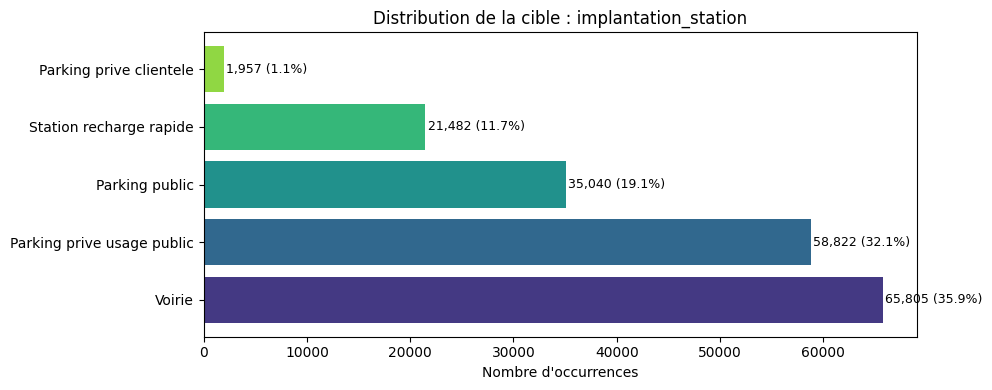

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
counts = df[TARGET].value_counts()
bars = ax.barh(counts.index, counts.values, color=sns.color_palette('viridis', len(counts)))
ax.set_xlabel('Nombre d\'occurrences')
ax.set_title('Distribution de la cible : implantation_station')
for bar, val in zip(bars, counts.values):
    ax.text(val + 200, bar.get_y() + bar.get_height()/2,
            f'{val:,} ({val/len(df)*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 5.Apprentissage supervisee

In [29]:
# Tester plusieurs algorithmes permet de choisir le plus adapté.

import time

classifiers = {
    'Decision Tree'  : DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest'  : RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    'KNN'            : KNeighborsClassifier(n_neighbors=5),
    'Gradient Boost' : GradientBoostingClassifier(random_state=42)
}

results = {}
for name, clf in classifiers.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    
    start = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start
    
    start = time.time()
    y_pred = pipe.predict(X_test)
    predict_time = time.time() - start

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    results[name] = {
        'Accuracy'      : round(acc, 4),
        'F1 weighted'   : round(f1, 4),
        'Temps train(s)': round(train_time, 2),
        'Temps pred(s)' : round(predict_time, 3)
    }
    print(f'{name} | Acc={acc:.4f} | F1={f1:.4f} | Train={train_time:.2f}s | Pred={predict_time:.3f}s')

results_df = pd.DataFrame(results).T
print(results_df.to_string())

Decision Tree | Acc=0.9308 | F1=0.9309 | Train=2.75s | Pred=0.079s
Random Forest | Acc=0.9260 | F1=0.9261 | Train=72.50s | Pred=2.309s
KNN | Acc=0.8431 | F1=0.8430 | Train=1.86s | Pred=2.389s
Gradient Boost | Acc=0.6457 | F1=0.6362 | Train=221.12s | Pred=0.408s
                Accuracy  F1 weighted  Temps train(s)  Temps pred(s)
Decision Tree     0.9308       0.9309            2.75          0.079
Random Forest     0.9260       0.9261           72.50          2.309
KNN               0.8431       0.8430            1.86          2.389
Gradient Boost    0.6457       0.6362          221.12          0.408


# Selection du meilleur modèle avec GridSearchCV 

In [ ]:
#Optimisation du meilleur modèle

from sklearn.model_selection import GridSearchCV

param_grid = {
    'clf__n_estimators'      : [100],
    'clf__max_depth'         : [10, None],
    'clf__class_weight'      : ['balanced', None]
}

pipe_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(random_state=42))
])

grid_search = GridSearchCV(
    pipe_rf, param_grid,
    cv=3, scoring='f1_weighted',
    n_jobs=1, verbose=1
)
# Entraînement sur 30% des données pour aller plus vite
X_gs, _, y_gs, _ = train_test_split(
    X_train, y_train,
    test_size=0.7,
    random_state=42,
    stratify=y_train
)

t0 = time.time()
grid_search.fit(X_train, y_train)


print(f'\nMeilleurs paramètres : {grid_search.best_params_}')
print(f'Meilleur score CV   : {grid_search.best_score_:.4f}')

best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test)

Fitting 3 folds for each of 4 candidates, totalling 12 fits



Meilleurs paramètres : {'clf__class_weight': None, 'clf__max_depth': None, 'clf__n_estimators': 100}
Meilleur score CV   : 0.9059


In [31]:
print(classification_report(y_test, y_pred_final,
                             target_names=le.classes_, zero_division=0))

                            precision    recall  f1-score   support

   Parking prive clientele       0.94      0.91      0.93       391
Parking prive usage public       0.94      0.94      0.94     11765
            Parking public       0.93      0.92      0.93      7008
   Station recharge rapide       0.90      0.90      0.90      4297
                    Voirie       0.93      0.94      0.94     13161

                  accuracy                           0.93     36622
                 macro avg       0.93      0.92      0.93     36622
              weighted avg       0.93      0.93      0.93     36622



# Matrice de confusion

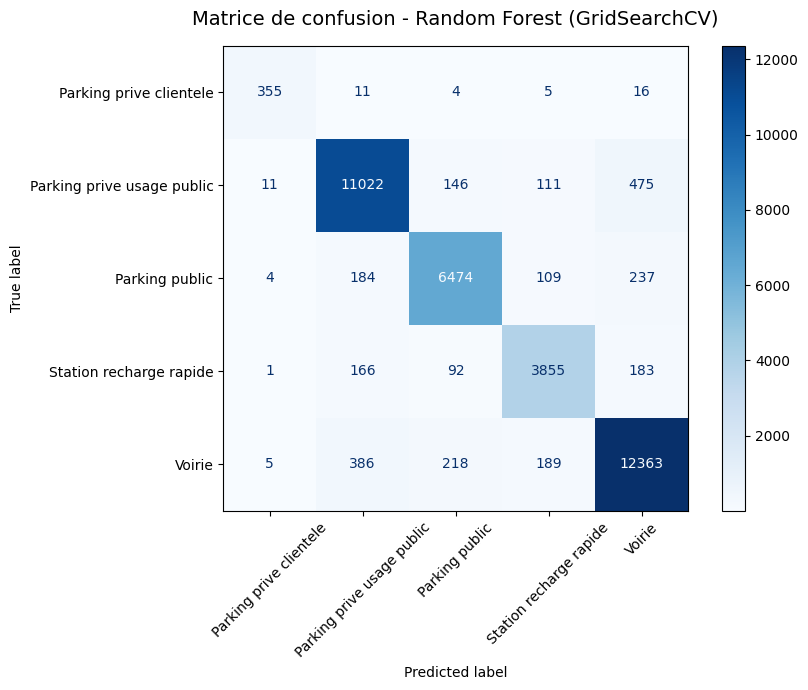


Matrice de confusion (valeurs brutes) :
Predit                      Parking prive clientele  Parking prive usage public  Parking public  Station recharge rapide  Voirie
Reel                                                                                                                            
Parking prive clientele                         355                          11               4                        5      16
Parking prive usage public                       11                       11022             146                      111     475
Parking public                                    4                         184            6474                      109     237
Station recharge rapide                           1                         166              92                     3855     183
Voirie                                            5                         386             218                      189   12363


In [33]:
# Matrice de confusion du meilleur modele (GridSearchCV)
fig, ax = plt.subplots(figsize=(9, 7))
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, colorbar=True, cmap='Blues', xticks_rotation=45)
ax.set_title('Matrice de confusion - Random Forest (GridSearchCV)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# Affichage de la matrice brute
print('\nMatrice de confusion (valeurs brutes) :')
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)
cm_df.index.name   = 'Reel'
cm_df.columns.name = 'Predit'
print(cm_df.to_string())

# Sauvegarde du modèle et préprocesseur

In [ ]:
import os
import joblib

BASE_DIR = r"chemin du dossier de sauvegarde : projet-ia-irve/Besoin_Client_3/models"
os.makedirs(os.path.join(BASE_DIR, 'models'), exist_ok=True)

# Sauvegarder le pipeline complet (préprocesseur + modèle) ET le label encoder
joblib.dump(best_model, os.path.join(BASE_DIR, 'models', 'classification_model.pkl'))
joblib.dump(le,         os.path.join(BASE_DIR, 'models', 'label_encoder_implantation.pkl'))

# Sauvegarder aussi la liste des features pour le script
import json
config = {'features_num': FEATURES_NUM, 'features_cat': FEATURES_CAT, 'target': TARGET}
with open(os.path.join(BASE_DIR, "models", "classification_config.json"), 'w') as f:
    json.dump(config, f)
